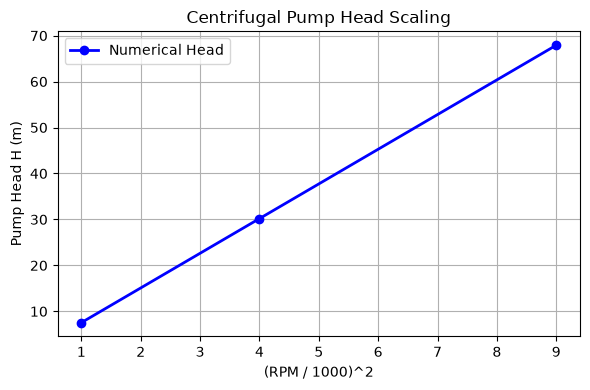

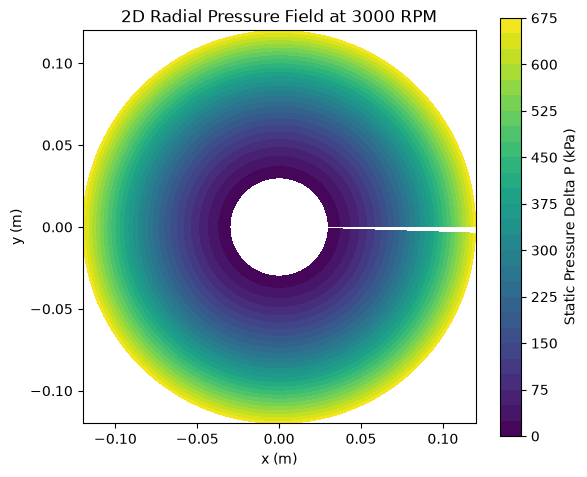

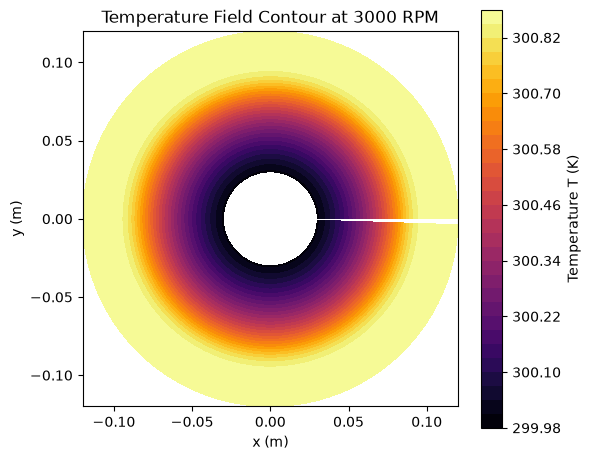

In [3]:
"""
  CFD & HT Lab - Experiment 3
  Topic: Flow and Heat Transfer in a Centrifugal Pump
  Student Name : Dev Pateliya
  Roll Number  : 23BME081
  Semester     : 7th Semester (B.Tech Mechanical Engineering)
"""

import numpy as np
import matplotlib.pyplot as plt

nr, ntheta = 100, 200
r1, r2 = 0.03, 0.12
b = 0.01

Re = 500
Tin = 300.0
Twall = 330.0
swirl = 0.85
wall_HTC = 120.0
loss_fraction = 0.04
iterations = 1200

rho, mu, cp, k = 997.0, 1.0e-3, 4180.0, 0.60
g = 9.81
Dh = 2 * b

r = np.linspace(r1, r2, nr)
theta = np.linspace(0, 2 * np.pi, ntheta, endpoint=False)
R, THETA = np.meshgrid(r, theta)

X = R * np.cos(THETA)
Y = R * np.sin(THETA)

U1 = (Re * mu) / (rho * Dh)
ur = (U1 * r1) / R

rpm_list = [1000, 2000, 3000]
head_list = []

for rpm in rpm_list:
    Omega = (2 * np.pi * rpm) / 60.0
    u_theta_abs = swirl * Omega * R
    u_theta_rel = (swirl - 1.0) * Omega * R
    
    p = 0.5 * rho * (Omega**2) * (R**2 - r1**2) - (12 * mu * U1 * r1 / b**2) * np.log(R / r1)
    
    delta_p = p[-1, -1] - p[0, 0]
    head = delta_p / (rho * g)
    head_list.append(head)

Omega_max = (2 * np.pi * rpm_list[-1]) / 60.0
u_theta_rel_max = (swirl - 1.0) * Omega_max * R

dr = (r2 - r1) / (nr - 1)
dtheta = 2 * np.pi / ntheta

T = np.ones((ntheta, nr)) * Tin
dt_thermal = 0.005

for it in range(iterations):
    T_old = T.copy()
    
    dT_dr = (T_old[:, 1:-1] - T_old[:, :-2]) / dr
    dT_dtheta = (np.roll(T_old[:, 1:-1], -1, axis=0) - T_old[:, 1:-1]) / dtheta
    
    d2T_dr2 = (T_old[:, 2:] - 2 * T_old[:, 1:-1] + T_old[:, :-2]) / (dr**2)
    
    ST = (2 * wall_HTC / b) * (Twall - T_old[:, 1:-1]) + rho * loss_fraction * (Omega_max**2) * R[:, 1:-1] * ur[:, 1:-1]
    
    conv = ur[:, 1:-1] * dT_dr + (u_theta_rel_max[:, 1:-1] / R[:, 1:-1]) * dT_dtheta
    diff = (k / (rho * cp)) * d2T_dr2
    
    T_cand = T_old[:, 1:-1] + dt_thermal * (diff + ST / (rho * cp) - conv)
    T[:, 1:-1] = 0.15 * T_old[:, 1:-1] + 0.85 * T_cand
    
    T[:, 0] = Tin
    T[:, -1] = T[:, -2]

rpm_norm_sq = [(rpm / 1000.0)**2 for rpm in rpm_list]

plt.figure(figsize=(6, 4))
plt.plot(rpm_norm_sq, head_list, 'bo-', linewidth=2, label='Numerical Head')
plt.xlabel('(RPM / 1000)^2')
plt.ylabel('Pump Head H (m)')
plt.title('Centrifugal Pump Head Scaling')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
plt.contourf(X, Y, p / 1000.0, levels=30, cmap='viridis')
plt.colorbar(label='Static Pressure Delta P (kPa)')
plt.title('2D Radial Pressure Field at 3000 RPM')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
plt.contourf(X, Y, T, levels=30, cmap='inferno')
plt.colorbar(label='Temperature T (K)')
plt.title('Temperature Field Contour at 3000 RPM')
plt.xlabel('x (m)')
plt.ylabel('y (m)')
plt.gca().set_aspect('equal')
plt.tight_layout()
plt.show()